# GLM

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf

In [ ]:
rng = np.random.default_rng(0)
n = 20000
x = rng.normal(0, 1.0, size=n)
y = rng.normal(0, 1.0, size=n)

# tuning curve
u = (x + y) / np.sqrt(2.0)

alpha = np.log(5.0)  
sigma = 0.6
eta = alpha - (u**2) / (2 * sigma**2)   # log-rate
lam = np.exp(eta)
spikes = rng.poisson(lam)

df = pd.DataFrame(dict(x=x, y=y, spikes=spikes))

In [ ]:
modelA = smf.glm("spikes ~ x + y + I(x**2) + I(y**2)", data=df, family=sm.families.Poisson()).fit()
print("\\nModel A (no xy) coefficients:")
print(modelA.summary())

def pseudo_r2(counts, mu):
    def ll(y, m):
        m = np.clip(m, 1e-12, None)
        return np.sum(y * np.log(m) - m)
    mu_null = np.full_like(counts, np.mean(counts))
    return 1.0 - ll(counts, mu) / ll(counts, mu_null)

muA = modelA.fittedvalues.values
print(f"\\nMcFadden pseudo-R^2 (Model A): {pseudo_r2(spikes, muA):.3f}")

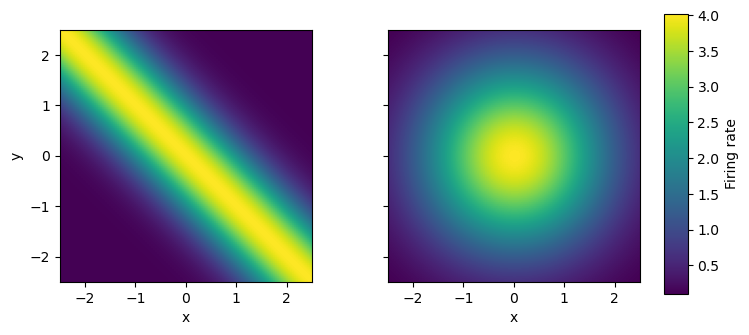

In [7]:
grid = np.linspace(-2.5, 2.5, 120)
Xg, Yg = np.meshgrid(grid, grid)
Ug = (Xg + Yg) / np.sqrt(2.0)
alpha = np.log(5.0); sigma = 0.6
eta_true_grid = alpha - (Ug**2) / (2 * sigma**2)
lam_true_grid = np.exp(eta_true_grid)

grid_df = pd.DataFrame({
    "x": Xg.ravel(),
    "y": Yg.ravel(),
    "x2": (Xg**2).ravel(),
    "y2": (Yg**2).ravel()
})
muA_grid = modelA.predict(grid_df[["x","y","x2","y2"]]).to_numpy().reshape(Xg.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

im0 = axes[0].imshow(lam_true_grid, origin="lower",
                     extent=[grid.min(), grid.max(), grid.min(), grid.max()],
                     aspect='equal')
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")

im1 = axes[1].imshow(muA_grid, origin="lower",
                     extent=[grid.min(), grid.max(), grid.min(), grid.max()],
                     aspect='equal')
axes[1].set_xlabel("x")

fig.subplots_adjust(right=0.85, wspace=0.3)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])  
cbar = fig.colorbar(im1, cax=cbar_ax)
cbar.set_label("Firing rate")
plt.show()
